# Does the void resolution depend on the profile?

The main result uses an idealised top hat, which is monotonic: the enclosed charge grows outward and never changes sign. A real void has an overdense ridge at its edge, so the charge is non-monotonic and *does* change sign — a stricter test.

Both profiles are run through the same comparison: the pure Galileon, sourced by the mass perturbation alone, against the symbiotic solution. If the resolution were an artefact of the top hat, the compensated void would expose it.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))
sys.path.insert(0, os.path.abspath(os.path.join('..', '..', 'main')))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import styling
import mixed_screening as ms
import robustness_sweep as sweep

styling.apply()

In [2]:
def load(path, runner, label):
    """Load a cached sweep, recomputing if missing or interrupted."""
    if os.path.exists(path):
        d = np.load(path)
        if 'complete' in d.files and bool(d['complete']):
            print(f'{label}: loaded cache'); return d
        print(f'{label}: cache incomplete -- recomputing')
    runner()
    return np.load(path)

d = load(sweep.OUT_VOID, sweep.run_void, 'void robustness')
x = d['x']
names = ['top-hat', 'compensated']

for nm in names:
    print(f"{nm:14s} min Delta/(eps*at*x)^2:  pure Galileon {np.nanmin(d['pure_'+nm]):+.4f}"
          f"   symbiotic {np.nanmin(d['mixed_'+nm]):+.4f}")

void robustness: loaded cache
top-hat        min Delta/(eps*at*x)^2:  pure Galileon -0.5802   symbiotic +0.2221
compensated    min Delta/(eps*at*x)^2:  pure Galileon -0.5740   symbiotic +0.1102


## Figure

Colour distinguishes the theory, line style the profile.

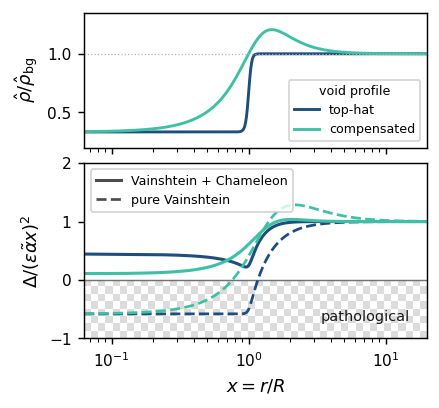

In [3]:
# Colour marks the density profile, line style marks the theory (solid =
# Vainshtein + Chameleon, dashed = pure Vainshtein) - the same two channels used
# throughout the paper. Delta < 0 is marked as absent, not tinted, since no real
# branch exists there.
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap

C_PROF = {'top-hat': styling.PROFILES['top-hat'],
          'compensated': styling.PROFILES['NFW-like']}
CHK_A, CHK_B, CHK_MM = '#ffffff', '#dcdcdc', 1.4
profiles = sweep.void_profiles()

fig, (axP, axD) = plt.subplots(2, 1, figsize=(styling.COL, styling.COL * 0.957),
                               sharex=True,
                               gridspec_kw={'height_ratios': [1, 1.3], 'hspace': 0.1})

xp = np.logspace(-1.2, 1.3, 400)
for nm in names:
    axP.plot(xp, profiles[nm](xp) / sweep.V_BG, color=C_PROF[nm], lw=1.6, label=nm)
axP.axhline(1.0, color='0.7', lw=0.7, ls=':')
axP.set_xscale('log'); axP.set_ylim(0.2, 1.35)
axP.set_ylabel(r'$\hat\rho/\hat\rho_{\rm bg}$')
axP.legend(fontsize=7, loc='lower right', title='void profile', title_fontsize=7)

for nm in names:
    axD.plot(x, d['pure_' + nm],  color=C_PROF[nm], lw=1.5, ls='--')
    axD.plot(x, d['mixed_' + nm], color=C_PROF[nm], lw=1.7, ls='-')

axD.set_xscale('log'); axD.set_xlim(x[0], x[-1]); axD.set_ylim(-1.0, 2.0)
axD.axhspan(-2, 0, color=CHK_A, zorder=0)
fig.canvas.draw()
bb = axD.get_window_extent().transformed(fig.dpi_scale_trans.inverted())
sq = CHK_MM / 25.4
nx = max(2, int(round(bb.width / sq))); ny = max(2, int(round(bb.height / sq)))
pat = (np.add.outer(np.arange(ny), np.arange(nx)) % 2).astype(float)
imc = axD.imshow(pat, cmap=ListedColormap([CHK_A, CHK_B]), extent=[0, 1, 0, 1],
                 transform=axD.transAxes, origin='lower', interpolation='nearest',
                 aspect='auto', zorder=0.5)
imc.set_clip_path(Rectangle((x[0], -2), x[-1] - x[0], 2, transform=axD.transData))
axD.axhline(0, color='0.45', lw=0.8, zorder=1.5)          # Delta = 0 reference

axD.set_xlabel(r'$x=r/R$')
axD.set_ylabel(r'$\Delta/(\epsilon\tilde\alpha x)^2$')
axD.text(0.82, 0.1, 'pathological', transform=axD.transAxes, ha='center',
         color='0.1', fontsize=8)
axD.legend(handles=[Line2D([], [], color='0.3', lw=1.7, ls='-', label='Vainshtein + Chameleon'),
                    Line2D([], [], color='0.3', lw=1.5, ls='--', label='pure Vainshtein')],
           fontsize=7, loc='upper left')

fig.savefig('robustness_void.png', dpi=200, bbox_inches='tight')
plt.show()
